In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
                 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
STOP_WORDS = set(stopwords.words('english'))
print("Setup complete.")

Setup complete.


In [2]:
paragraph = (
    "My favorite topic is space exploration because it combines science, engineering, and imagination. "
    "Modern telescopes help researchers observe distant planets, stars, and galaxies. "
    "Robotic spacecraft can travel through harsh environments and send valuable information back to Earth. "
    "These discoveries help us understand how the universe formed and whether life might exist elsewhere. "
    "I also enjoy learning how astronauts prepare for missions and how teams solve problems in space. "
    "In the future, new technology may make exploration safer and allow people to study the Moon and Mars more closely."
)

# Lowercase and remove punctuation using re.
clean_text = re.sub(r'[^a-zA-Z0-9\s]', '', paragraph.lower())
sentences = sent_tokenize(paragraph)
tokens = word_tokenize(clean_text)

print("Clean text:\n", clean_text)
print("\nSentences:")
for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")
print("\nWord tokens:", tokens)

Clean text:
 my favorite topic is space exploration because it combines science engineering and imagination modern telescopes help researchers observe distant planets stars and galaxies robotic spacecraft can travel through harsh environments and send valuable information back to earth these discoveries help us understand how the universe formed and whether life might exist elsewhere i also enjoy learning how astronauts prepare for missions and how teams solve problems in space in the future new technology may make exploration safer and allow people to study the moon and mars more closely

Sentences:
1. My favorite topic is space exploration because it combines science, engineering, and imagination.
2. Modern telescopes help researchers observe distant planets, stars, and galaxies.
3. Robotic spacecraft can travel through harsh environments and send valuable information back to Earth.
4. These discoveries help us understand how the universe formed and whether life might exist elsewhere

In [3]:
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print("Python split():", split_tokens)
print("\nNLTK word_tokenize():", nltk_tokens)
print("\nToken counts:", len(split_tokens), "vs", len(nltk_tokens))

Python split(): ['My', 'favorite', 'topic', 'is', 'space', 'exploration', 'because', 'it', 'combines', 'science,', 'engineering,', 'and', 'imagination.', 'Modern', 'telescopes', 'help', 'researchers', 'observe', 'distant', 'planets,', 'stars,', 'and', 'galaxies.', 'Robotic', 'spacecraft', 'can', 'travel', 'through', 'harsh', 'environments', 'and', 'send', 'valuable', 'information', 'back', 'to', 'Earth.', 'These', 'discoveries', 'help', 'us', 'understand', 'how', 'the', 'universe', 'formed', 'and', 'whether', 'life', 'might', 'exist', 'elsewhere.', 'I', 'also', 'enjoy', 'learning', 'how', 'astronauts', 'prepare', 'for', 'missions', 'and', 'how', 'teams', 'solve', 'problems', 'in', 'space.', 'In', 'the', 'future,', 'new', 'technology', 'may', 'make', 'exploration', 'safer', 'and', 'allow', 'people', 'to', 'study', 'the', 'Moon', 'and', 'Mars', 'more', 'closely.']

NLTK word_tokenize(): ['My', 'favorite', 'topic', 'is', 'space', 'exploration', 'because', 'it', 'combines', 'science', ',',

Tokens excluding stopwords: ['favorite', 'topic', 'space', 'exploration', 'combines', 'science', 'engineering', 'imagination', 'modern', 'telescopes', 'help', 'researchers', 'observe', 'distant', 'planets', 'stars', 'galaxies', 'robotic', 'spacecraft', 'travel', 'harsh', 'environments', 'send', 'valuable', 'information', 'back', 'earth', 'discoveries', 'help', 'us', 'understand', 'universe', 'formed', 'whether', 'life', 'might', 'exist', 'elsewhere', 'also', 'enjoy', 'learning', 'astronauts', 'prepare', 'missions', 'teams', 'solve', 'problems', 'space', 'future', 'new', 'technology', 'may', 'make', 'exploration', 'safer', 'allow', 'people', 'study', 'moon', 'mars', 'closely']

Frequency distribution:
space: 2
exploration: 2
help: 2
favorite: 1
topic: 1
combines: 1
science: 1
engineering: 1
imagination: 1
modern: 1
telescopes: 1
researchers: 1
observe: 1
distant: 1
planets: 1
stars: 1
galaxies: 1
robotic: 1
spacecraft: 1
travel: 1
harsh: 1
environments: 1
send: 1
valuable: 1
information

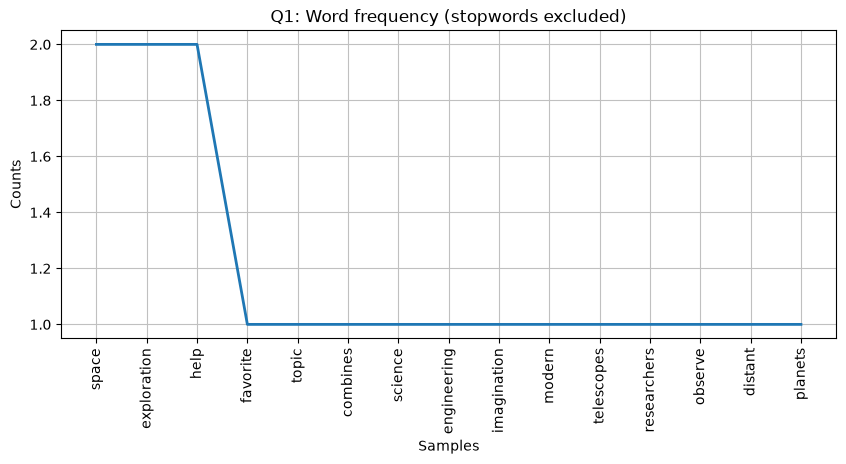

In [4]:
raw_tokens = word_tokenize(paragraph.lower())
alphabetic_tokens = [t for t in raw_tokens if re.fullmatch(r"[a-z]+", t)]
filtered_tokens = [t for t in alphabetic_tokens if t not in STOP_WORDS]
frequency = nltk.FreqDist(filtered_tokens)

print("Tokens excluding stopwords:", filtered_tokens)
print("\nFrequency distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

plt.figure(figsize=(10, 4))
frequency.plot(15, title="Q1: Word frequency (stopwords excluded)")
plt.show()

In [5]:
alphabetic_words = re.findall(r"[A-Za-z]+", paragraph.lower())
q2_words = [w for w in alphabetic_words if w not in STOP_WORDS]

porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [porter.stem(w) for w in q2_words]
lemmatized_words = [lemmatizer.lemmatize(w) for w in q2_words]

comparison_q2 = pd.DataFrame({
    "Original": q2_words,
    "Porter stem": stemmed_words,
    "WordNet lemma (noun default)": lemmatized_words
})
print("Alphabetic words:", alphabetic_words)
print("\nAfter stopword removal:", q2_words)
display(comparison_q2)

Alphabetic words: ['my', 'favorite', 'topic', 'is', 'space', 'exploration', 'because', 'it', 'combines', 'science', 'engineering', 'and', 'imagination', 'modern', 'telescopes', 'help', 'researchers', 'observe', 'distant', 'planets', 'stars', 'and', 'galaxies', 'robotic', 'spacecraft', 'can', 'travel', 'through', 'harsh', 'environments', 'and', 'send', 'valuable', 'information', 'back', 'to', 'earth', 'these', 'discoveries', 'help', 'us', 'understand', 'how', 'the', 'universe', 'formed', 'and', 'whether', 'life', 'might', 'exist', 'elsewhere', 'i', 'also', 'enjoy', 'learning', 'how', 'astronauts', 'prepare', 'for', 'missions', 'and', 'how', 'teams', 'solve', 'problems', 'in', 'space', 'in', 'the', 'future', 'new', 'technology', 'may', 'make', 'exploration', 'safer', 'and', 'allow', 'people', 'to', 'study', 'the', 'moon', 'and', 'mars', 'more', 'closely']

After stopword removal: ['favorite', 'topic', 'space', 'exploration', 'combines', 'science', 'engineering', 'imagination', 'modern', 

,Original,Porter stem,WordNet lemma (noun default)
0,favorite,favorit,favorite
1,topic,topic,topic
2,space,space,space
3,exploration,explor,exploration
4,combines,combin,combine
...,...,...,...
56,people,peopl,people
57,study,studi,study
58,moon,moon,moon
59,mars,mar,mar


In [6]:
def nltk_pos_to_wordnet(tag):
    if tag.startswith('J'):
        return 'a'
    if tag.startswith('V'):
        return 'v'
    if tag.startswith('R'):
        return 'r'
    return 'n'

tagged_words = nltk.pos_tag(q2_words)
pos_lemmas = [
    lemmatizer.lemmatize(word, nltk_pos_to_wordnet(tag))
    for word, tag in tagged_words
]
display(pd.DataFrame({
    "Word": q2_words,
    "NLTK POS": [tag for _, tag in tagged_words],
    "POS-aware lemma": pos_lemmas
}))

,Word,NLTK POS,POS-aware lemma
0,favorite,JJ,favorite
1,topic,NN,topic
2,space,NN,space
3,exploration,NN,exploration
4,combines,NNS,combine
...,...,...,...
56,people,NNS,people
57,study,VBP,study
58,moon,JJ,moon
59,mars,NNS,mar


In [7]:
texts = [
    "Electric buses reduce city air pollution and make public transport quieter. Cities are building charging stations for cleaner journeys.",
    "A new smartphone uses a fast processor, a bright screen, and a long lasting battery. The camera captures detailed photos.",
    "Community gardens provide fresh vegetables and create green spaces. Volunteers share gardening skills and support local neighborhoods."
]
text_labels = ["Electric buses", "Smartphone", "Community gardens"]

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

count_vectorizer = CountVectorizer(stop_words="english")
bow_matrix = count_vectorizer.fit_transform(texts)
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    index=text_labels,
    columns=count_vectorizer.get_feature_names_out()
)
print("Bag of Words matrix:")
display(bow_df)

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    index=text_labels,
    columns=tfidf_vectorizer.get_feature_names_out()
)
print("TF-IDF matrix:")
display(tfidf_df.round(3))

feature_names = tfidf_vectorizer.get_feature_names_out()
print("\nTop 3 TF-IDF keywords in each text:")
for i, label in enumerate(text_labels):
    row = tfidf_matrix[i].toarray().ravel()
    top_indices = row.argsort()[::-1][:3]
    print(label, [(feature_names[j], round(float(row[j]), 3)) for j in top_indices])

Bag of Words matrix:


,air,battery,bright,building,buses,camera,captures,charging,cities,city,...,share,skills,smartphone,spaces,stations,support,transport,uses,vegetables,volunteers
Electric buses,1,0,0,1,1,0,0,1,1,1,...,0,0,0,0,1,0,1,0,0,0
Smartphone,0,1,1,0,0,1,1,0,0,0,...,0,0,1,0,0,0,0,1,0,0
Community gardens,0,0,0,0,0,0,0,0,0,0,...,1,1,0,1,0,1,0,0,1,1


TF-IDF matrix:


,air,battery,bright,building,buses,camera,captures,charging,cities,city,...,share,skills,smartphone,spaces,stations,support,transport,uses,vegetables,volunteers
Electric buses,0.25,0.000,0.000,0.25,0.25,0.000,0.000,0.25,0.25,0.25,...,0.000,0.000,0.000,0.000,0.25,0.000,0.25,0.000,0.000,0.000
Smartphone,0.00,0.267,0.267,0.00,0.00,0.267,0.267,0.00,0.00,0.00,...,0.000,0.000,0.267,0.000,0.00,0.000,0.00,0.267,0.000,0.000
Community gardens,0.00,0.000,0.000,0.00,0.00,0.000,0.000,0.00,0.00,0.00,...,0.258,0.258,0.000,0.258,0.00,0.258,0.00,0.000,0.258,0.258



Top 3 TF-IDF keywords in each text:
Electric buses [('transport', 0.25), ('quieter', 0.25), ('reduce', 0.25)]
Smartphone [('uses', 0.267), ('screen', 0.267), ('smartphone', 0.267)]
Community gardens [('volunteers', 0.258), ('vegetables', 0.258), ('support', 0.258)]


In [8]:
ai_text = (
    "Artificial intelligence learns patterns from data and helps computers make predictions. "
    "Machine learning systems can recognize images, understand language, and support decisions. "
    "AI is used in healthcare, education, transport, and scientific research."
)
blockchain_text = (
    "Blockchain stores records in linked digital blocks shared across a network. "
    "Cryptography helps protect transactions and makes records difficult to alter. "
    "Blockchain is used in digital payments, supply chains, and secure record keeping."
)

def preprocess_for_similarity(text):
    return word_tokenize(re.sub(r"[^a-zA-Z0-9\s]", " ", text.lower()))

ai_tokens = preprocess_for_similarity(ai_text)
blockchain_tokens = preprocess_for_similarity(blockchain_text)
set_ai, set_blockchain = set(ai_tokens), set(blockchain_tokens)

jaccard = len(set_ai & set_blockchain) / len(set_ai | set_blockchain)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
sim_vectorizer = TfidfVectorizer()
tfidf_pair = sim_vectorizer.fit_transform([ai_text, blockchain_text])
cosine = cosine_similarity(tfidf_pair[0:1], tfidf_pair[1:2])[0, 0]

print("AI tokens:", ai_tokens)
print("\nBlockchain tokens:", blockchain_tokens)
print(f"Jaccard similarity: {jaccard:.4f}")
print(f"TF-IDF cosine similarity: {cosine:.4f}")

AI tokens: ['artificial', 'intelligence', 'learns', 'patterns', 'from', 'data', 'and', 'helps', 'computers', 'make', 'predictions', 'machine', 'learning', 'systems', 'can', 'recognize', 'images', 'understand', 'language', 'and', 'support', 'decisions', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transport', 'and', 'scientific', 'research']

Blockchain tokens: ['blockchain', 'stores', 'records', 'in', 'linked', 'digital', 'blocks', 'shared', 'across', 'a', 'network', 'cryptography', 'helps', 'protect', 'transactions', 'and', 'makes', 'records', 'difficult', 'to', 'alter', 'blockchain', 'is', 'used', 'in', 'digital', 'payments', 'supply', 'chains', 'and', 'secure', 'record', 'keeping']
Jaccard similarity: 0.0943
TF-IDF cosine similarity: 0.1639


In [10]:
!pip install textblob

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [12]:
reviews = [
    "The headphones sound excellent, feel comfortable, and the battery lasts all day.",
    "The delivery was late and the device stopped working after two days. Very disappointing.",
    "The package arrived today. The product has a screen, two buttons, and a charging cable.",
    "Customer support was helpful and quickly replaced my faulty charger.",
    "The app crashes often and the latest update made it slower."
]

from textblob import TextBlob

def sentiment_label(polarity, threshold=0.05):
    if polarity > threshold:
        return "Positive"
    elif polarity < -threshold:
        return "Negative"
    return "Neutral"

results = []
for review in reviews:
    sentiment = TextBlob(review).sentiment
    results.append({
        "Review": review,
        "Polarity": float(sentiment.polarity),
        "Subjectivity": float(sentiment.subjectivity),
        "Sentiment": sentiment_label(sentiment.polarity)
    })

reviews_df = pd.DataFrame(results)
display(reviews_df)

,Review,Polarity,Subjectivity,Sentiment
0,"The headphones sound excellent, feel comfortab...",0.600000,0.733333,Positive
1,The delivery was late and the device stopped w...,-0.540000,0.755000,Negative
2,The package arrived today. The product has a s...,0.000000,0.000000,Neutral
3,Customer support was helpful and quickly repla...,0.333333,0.500000,Positive
4,The app crashes often and the latest update ma...,0.500000,0.900000,Positive


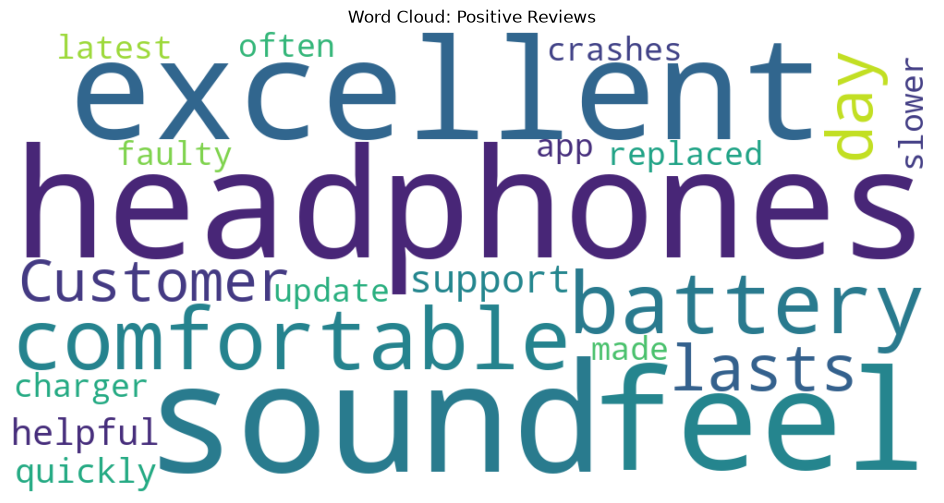

In [15]:
positive_reviews = reviews_df.loc[
    reviews_df["Sentiment"] == "Positive", "Review"
].tolist()

if positive_reviews:
    from wordcloud import WordCloud
    positive_text = " ".join(positive_reviews)
    word_cloud = WordCloud(
        width=1000, height=500, background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(word_cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud: Positive Reviews")
    plt.show()
else:
    print("No positive reviews were classified.")

In [16]:
training_text = (
    "Technology changes the way people learn, work, and communicate. "
    "Digital tools help students explore ideas and practice new skills. "
    "A computer can organize information, solve calculations, and display useful results. "
    "People use the internet to read articles, watch lessons, and share projects. "
    "Good technology should be reliable, accessible, and safe. "
    "Teachers can combine online resources with classroom discussion. "
    "Engineers test their designs and improve them through feedback. "
    "In the future, intelligent systems may help communities solve difficult problems. "
    "People will still need curiosity, creativity, and careful thinking. "
    "Learning how technology works helps everyone make better decisions."
)
print("Training paragraph word count:", len(training_text.split()))

Training paragraph word count: 96


In [18]:
# Use Keras Tokenizer and sequence utilities.
try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense
    from tensorflow.keras.utils import to_categorical
except ImportError:
    from keras.preprocessing.text import Tokenizer
    from keras.preprocessing.sequence import pad_sequences
    from keras.models import Sequential
    from keras.layers import Embedding, LSTM, Dense
    from keras.utils import to_categorical

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for sentence in training_text.split("."):
    sentence = sentence.strip()
    if sentence:
        sequence = tokenizer.texts_to_sequences([sentence])[0]
        for i in range(1, len(sequence)):
            input_sequences.append(sequence[:i + 1])

max_sequence_len = max(len(seq) for seq in input_sequences)
sequences = pad_sequences(
    input_sequences, maxlen=max_sequence_len, padding="pre"
)

X_lstm = sequences[:, :-1]
y_lstm = to_categorical(sequences[:, -1], num_classes=total_words)

print("Vocabulary size:", total_words - 1)
print("Training sequences:", len(input_sequences))
print("Maximum sequence length:", max_sequence_len)

Vocabulary size: 81
Training sequences: 86
Maximum sequence length: 12


In [19]:
lstm_model = Sequential([
    Embedding(input_dim=total_words, output_dim=32),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
lstm_model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
history = lstm_model.fit(
    X_lstm, y_lstm, epochs=100, verbose=0
)
print("LSTM training complete.")
print("Final training accuracy:", round(float(history.history["accuracy"][-1]), 4))

LSTM training complete.
Final training accuracy: 0.814


In [20]:
def generate_text(seed_word, next_words=12):
    generated = seed_word.lower().strip()
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]
        token_list = pad_sequences(
            [token_list], maxlen=max_sequence_len - 1, padding="pre"
        )
        probabilities = lstm_model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(probabilities))

        predicted_word = None
        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                predicted_word = word
                break

        if predicted_word is None:
            break
        generated += " " + predicted_word
    return generated

seed_word = "technology"
print("Generated text from seed:", seed_word)
for i in range(3):
    print(f"Line {i + 1}: {generate_text(seed_word, next_words=12)}")

Generated text from seed: technology
Line 1: technology the the intelligent people learn work and communicate communicate difficult problems problems
Line 2: technology the the intelligent people learn work and communicate communicate difficult problems problems
Line 3: technology the the intelligent people learn work and communicate communicate difficult problems problems
